In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# 4000 бичлэг, 8 шинж, 2 анги — зээлийн default (1) / сайн зээл (0)
X, y = make_classification(
    n_samples=4000, n_features=8, n_informative=5,
    n_redundant=1, weights=[0.94, 0.06],
    flip_y=0.03, class_sep=1.1, random_state=4)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print("X.shape:", X.shape)
print("X_train.shape:", X_train.shape)
print("X_test.shape:", X_test.shape)
print(y_test.sum(), "эерэг /", len(y_test))

X.shape: (4000, 8)
X_train.shape: (3000, 8)
X_test.shape: (1000, 8)
73 эерэг / 1000


X.shape: (4000, 8)
X_train.shape: (3000, 8)
X_test.shape: (1000, 8)
73 эерэг / 1000

### А1 (4 оноо) — Регресс ба ангиллын ялгаа

**Регресс** нь тасралтгүй тоон утгыг таамагладаг (жишээ нь: үнэ, температур, борлуулалт), харин **ангилал** нь дискрет категори эсвэл ангийг таамагладаг (жишээ нь: тийм/үгүй, spam/биш). Регрессийн гаралт нь бодит тооны муж, ангиллын гаралт нь хязгаарлагдмал олонлог байна. Регресс нь алдааны квадрат нийлбэрийг бууруулахыг зорьдог бол ангилал нь ангийн хил хязгаарыг оновчтой болгохыг зорьдог.

**Асуудлуудын ангилал:**
- **(a) Ирэх сарын борлуулалтын дүнг таамаглах** → **Регресс** (тасралтгүй тоон утга)
- **(b) Харилцагч дараагийн сард гарч эсэхийг таамаглах** → **Ангилал** (0/1, гарна/гарахгүй)
- **(c) Зээлийн хүсэлтийг зөвшөөрөх эсэх** → **Ангилал** (0/1, зөвшөөрөх/татгалзах)

### А2 (4 оноо) — Шугаман регрессийг 0/1 ангилалд ашиглах асуудлууд

**Асуудал 1: Гаралт нь [0,1] мужаас гадуур гарах.** Шугаман регресс нь y = w·x + b хэлбэртэй тул ямар ч бодит тоог гаргаж болно. Гэвч 0/1 ангилалд магадлал нь [0,1] мужид байх ёстой. Жишээ нь: хэрэв шугаман загвар 1.5 эсвэл -0.3 гэж таамаглавал эдгээр нь хүчинтэй магадлал биш юм.

**Асуудал 2: Алдааны функц тохиромжгүй.** MSE (Mean Squared Error) нь ангиллын хувьд тохиромжгүй, учир нь энэ нь магадлалын тархалтыг зөв загварчлахгүй, мөн sigmoid функцтэй хослуулахад non-convex болдог (орон нутгийн минимумд гацах эрсдэлтэй).

**Логистик регресс хэрхэн шийддэг вэ:**
1. Шугаман гаралтыг **сигмоид функц**-ээр дамжуулж [0,1] мужид оруулдаг: σ(z) = 1/(1+e⁻ᶻ).
2. **Log loss (binary cross-entropy)** ашигладаг бөгөөд энэ нь convex функц тул градиент буулгалтаар глобал минимумд хүрэх боломжтой.

### А3 (4 оноо) — Сигмоид функц

**(a) σ(0) = 1/(1+e⁰) = 1/(1+1) = 0.5**

**(b) z → −∞ үеийн хязгаар: σ(z) → 0** (учир нь e⁻ᶻ → +∞, тиймээс 1/(1+∞) → 0)

**(c) z → +∞ үеийн хязгаар: σ(z) → 1** (учир нь e⁻ᶻ → 0, тиймээс 1/(1+0) → 1)

**Яагаад магадлал гаргахад тохиромжтой вэ:** Сигмоид функцийн гаралт нь үргэлж (0,1) мужид байдаг тул магадлал гэж тайлбарлаж болно. Мөн энэ нь монотон, дифференциалагдах бөгөөд түүний уламжлал нь σ'(z) = σ(z)(1−σ(z)) гэсэн энгийн хэлбэртэй.

**σ(−z) = 1 − σ(z) тэгшитгэлийн утга:** Энэ нь сигмоид функцийн тэгш хэмийг илэрхийлнэ. Хэрэв z-ийн утгаар "эерэг" ангийн магадлал σ(z) бол, "сөрөг" ангийн магадлал нь σ(−z) = 1 − σ(z) байна. Энэ нь хоёр ангийн магадлалын нийлбэр 1 байх ёстой гэсэн зарчимтай нийцдэг.

### А4 (4 оноо) — Log loss ба MSE харьцуулалт

**Log loss (binary cross-entropy):**
L = −(1/N) Σ [yᵢ log(pᵢ) + (1−yᵢ) log(1−pᵢ)]

**MSE:**
L = (1/N) Σ (yᵢ − pᵢ)²

**Яагаад MSE биш log loss ашигладаг вэ:**
1. **Convexity:** Log loss нь логистик регрессийн параметрүүдийн хувьд convex функц бөгөөд градиент буулгалт нь глобал минимумд хүрнэ. Харин MSE нь sigmoid-тай хослуулахад non-convex болж, орон нутгийн минимумд гацах эрсдэлтэй.
2. **Торгуулийн шинж чанар:** Log loss нь буруу таамаглалыг илүү хүчтэй торгодог. Жишээ нь: хэрэв y=1 бөгөөд p=0.1 бол log loss = −log(0.1) = 2.3026 (маш их торгууль), харин MSE = (1−0.1)² = 0.81 (харьцангуй бага).
3. **«Итгэлтэй буруу таамаглал»:** Хэрэв загвар y=1 гэж итгэлтэй (p=0.99) таамагласан ч бодит утга y=0 бол log loss = −log(0.01) = 4.6052 гэж маш их торгууль өгнө. Энэ нь загварыг хэт итгэлтэй буруу таамаглалаас сэргийлдэг.

### А5 (4 оноо) — Precision ба Recall

**Precision (нарийвчлал):** Таамагласан эерэгүүдийн хэд нь бодитоор эерэг вэ? P = TP/(TP+FP)

**Recall (бүрэн байдал):** Бодит эерэгүүдийн хэд нь таамаглагдсан вэ? R = TP/(TP+FN)

**Тохиолдлууд:**
- **(a) Спам шүүлт:** **Precision**-ийг гол болгох хэрэгтэй, учир нь чухал имэйлийг спам гэж буруу ангилах нь (FP) хэрэглэгчид маш их хор хөнөөлтэй. Хэрэв precision бага бол олон чухал имэйл спам руу орно.
- **(b) Зээлийн default таамаглал:** **Recall**-ийг гол болгох хэрэгтэй, учир нь default болох харилцагчийг алдаж (FN) банкинд их хэмжээний алдагдал авчирна. Precision бага байх нь зөвхөн нэмэлт шалгалт хийхэд хүргэнэ.
- **(c) Халдварт өвчний шинжилгээ:** **Recall**-ийг гол болгох хэрэгтэй, учир нь өвчтэй хүнийг алдаж (FN) тархалтыг нэмэгдүүлж, амь насанд аюултай. Precision бага байх нь зөвхөн нэмэлт шинжилгээ хийхэд хүргэнэ.

In [2]:
import numpy as np

def sigmoid(z):
    """
    Sigmoid функц: σ(z) = 1 / (1 + e^(-z))
    Overflow-оос сэргийлэхийн тулд np.clip ашиглана.
    """
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

# Шалгах
z_vals = np.array([-1000, -2, 0, 2, 1000])
result = sigmoid(z_vals)

print("z утгууд:", z_vals)
print("sigmoid(z):", result)
print()
for z, s in zip(z_vals, result):
    print(f"σ({z:>6}) = {s:.4f}")

z утгууд: [-1000    -2     0     2  1000]
sigmoid(z): [7.12457641e-218 1.19202922e-001 5.00000000e-001 8.80797078e-001
 1.00000000e+000]

σ( -1000) = 0.0000
σ(    -2) = 0.1192
σ(     0) = 0.5000
σ(     2) = 0.8808
σ(  1000) = 1.0000


### Б1 — Тайлбар

**Яагаад z маш сөрөг үед np.exp(−z) overflow болдог вэ?** 
z = −1000 үед −z = +1000 болж, e¹⁰⁰⁰ нь маш том тоо (≈10⁴³⁴) болж, компьютерийн floating point-ийн хязгаараас (≈1.8×10³⁰⁸) хэтэрч overflow болно. Иймд np.clip(z, −500, 500) ашиглан z-ийг −500-аас 500-ийн хооронд хязгаарлана. e⁵⁰⁰ ≈ 1.4×10²¹⁷ нь floating point-д багтах хэмжээтэй.

**Яагаад сигмоид нь 0 болж унадаггүй вэ?** 
Математикийн хувьд z → −∞ үед σ(z) → 0 боловч хэзээ ч яг 0 болохгүй (асимптот). Компьютер дээр маш бага утга (жишээ нь 10⁻²¹⁷) гарч болох ч энэ нь 0 биш. Энэ нь магадлалын хувьд чухал — ямар ч үед бага ч гэсэн магадлал байх ёстой.

In [3]:
import numpy as np

def log_loss_manual(y, p, eps=1e-12):
    """
    Log loss-ийг гараар тооцоолох.
    y: бодит утга (0 эсвэл 1)
    p: таамагласан магадлал
    eps: log(0)-оос сэргийлэх clip утга
    """
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# Шалгах жишээнүүд
examples = [
    (1, 0.9, "зөв бөгөөд итгэлтэй"),
    (1, 0.1, "буруу бөгөөд итгэлтэй ← хамгийн муу"),
    (0, 0.9, "мөн адил их торгууль"),
]

print("Log loss шалгалт:")
print("-" * 55)
for y, p, desc in examples:
    loss = log_loss_manual(np.array([y]), np.array([p]))
    print(f"(y={y}, p={p}) → {loss:.4f}  # {desc}")

print()
print(f"ln(10) = {np.log(10):.4f}")
print(f"−ln(0.1) = {-np.log(0.1):.4f}")

Log loss шалгалт:
-------------------------------------------------------
(y=1, p=0.9) → 0.1054  # зөв бөгөөд итгэлтэй
(y=1, p=0.1) → 2.3026  # буруу бөгөөд итгэлтэй ← хамгийн муу
(y=0, p=0.9) → 2.3026  # мөн адил их торгууль

ln(10) = 2.3026
−ln(0.1) = 2.3026


### Б2 — Тайлбар

**Яагаад 2.3026 гэсэн тоо гарч байна вэ?** 
Энэ нь ln(10) = 2.302585... юм. Учир нь p = 0.1 үед −log(0.1) = −log(10⁻¹) = log(10) = ln(10) ≈ 2.3026. Хэрэв загвар y=1 гэж итгэлтэй (p=0.1 гэж буруу) таамаглавал энэ нь хамгийн их торгуулийн нэг юм. p утгыг 1e-12 хүртэл clip хийх нь log(0) = −∞ болохоос сэргийлнэ.

In [4]:
from sklearn.preprocessing import StandardScaler

# a) Scale хийх (train-д fit, test-д transform)
scaler = StandardScaler()
Xs_train = scaler.fit_transform(X_train)
Xs_test = scaler.transform(X_test)

# b) Bias багана нэмэх
Xb = np.c_[np.ones(Xs_train.shape[0]), Xs_train]
Xb_test = np.c_[np.ones(Xs_test.shape[0]), Xs_test]

# c) Жинг тэгээс эхлүүлэх
w = np.zeros(Xb.shape[1])

# d) Градиент буулгалт
def compute_gradient(Xb, y, w):
    N = len(y)
    p = sigmoid(Xb @ w)
    return Xb.T @ (p - y) / N

def compute_loss(Xb, y, w):
    p = sigmoid(Xb @ w)
    return log_loss_manual(y, p)

# e) Сургалт
learning_rate = 0.1
n_epochs = 600
losses = []

for epoch in range(n_epochs):
    loss = compute_loss(Xb, y_train, w)
    losses.append(loss)
    grad = compute_gradient(Xb, y_train, w)
    w = w - learning_rate * grad

print(f"Эхний алдагдал: {losses[0]:.6f}")
print(f"Сүүлийн алдагдал: {losses[-1]:.6f}")

Эхний алдагдал: 0.693147
Сүүлийн алдагдал: 0.162477


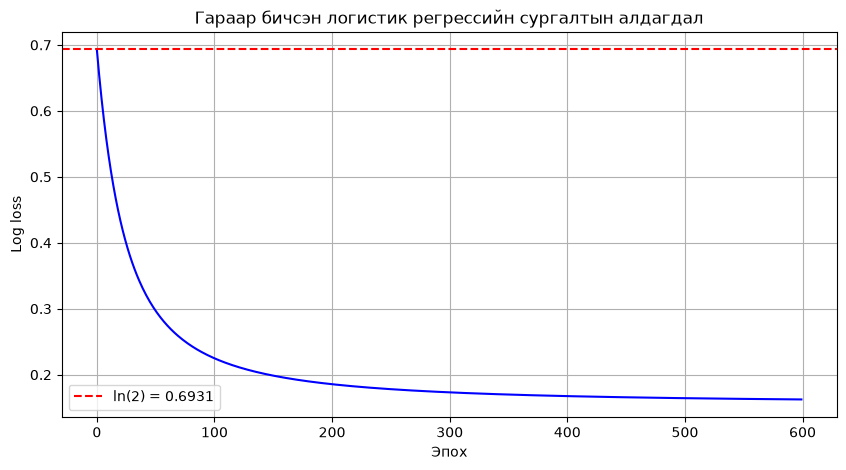

Б3 — Тестийн AUC: 0.8766


In [5]:
from sklearn.metrics import roc_auc_score

# f) График зурах
plt.figure(figsize=(10, 5))
plt.plot(range(n_epochs), losses, 'b-', linewidth=1.5)
plt.xlabel('Эпох')
plt.ylabel('Log loss')
plt.title('Гараар бичсэн логистик регрессийн сургалтын алдагдал')
plt.axhline(y=np.log(2), color='r', linestyle='--', label=f'ln(2) = {np.log(2):.4f}')
plt.legend()
plt.grid(True)
plt.show()

# g) Тестийн AUC
p_test_manual = sigmoid(Xb_test @ w)
auc_manual = roc_auc_score(y_test, p_test_manual)
print(f"Б3 — Тестийн AUC: {auc_manual:.4f}")

### Б3 — Тайлбар

**Асуулт: эхний алдагдал яагаад яг ln 2 = 0.693 вэ?**
w = 0 үед бүх жин тэг байна. Тэгвэл z = Xb @ w = 0, тиймээс σ(0) = 0.5. Бүх таамаглал p = 0.5 байна. Log loss томьёо:
L = −(1/N) Σ [yᵢ log(0.5) + (1−yᵢ) log(0.5)] = −(1/N) · (−ln2) · N = ln2 ≈ 0.6931
Тиймээс эхний алдагдал яг ln(2) байна. Энэ нь загвар эхэндээ "мэдэхгүй" байгаагийн илрэл — бүх ангид 50% магадлал өгч байна.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, roc_auc_score

# Pipeline бүтээх
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000, random_state=42)
)

# Сургах
model.fit(X_train, y_train)

# Таамаглал — P(default)
p_sklearn = model.predict_proba(X_test)[:, 1]

# a) Тестийн log loss
test_logloss = log_loss(y_test, p_sklearn)
print(f"В1a — Тестийн log loss: {test_logloss:.4f}")

# b) ROC-AUC
test_auc = roc_auc_score(y_test, p_sklearn)
print(f"В1b — Тестийн ROC-AUC: {test_auc:.4f}")

# predict_proba ба predict-ийн ялгаа
y_pred_class = model.predict(X_test)
print(f"\npredict_proba-ийн эхний 5 утга: {p_sklearn[:5]}")
print(f"predict-ийн эхний 5 утга: {y_pred_class[:5]}")

В1a — Тестийн log loss: 0.1489
В1b — Тестийн ROC-AUC: 0.8710

predict_proba-ийн эхний 5 утга: [0.08918045 0.10877157 0.17402937 0.0106295  0.01548057]
predict-ийн эхний 5 утга: [0 0 0 0 0]


### В1 — Тайлбар

**c) Асуулт: Б3-ын гар аргаар гаргасан AUC ба энэ AUC яагаад ижил түвшинд гарч байна вэ?**
Учир нь хоёулаа ижил математик загварыг (логистик регресс) ижил дата дээр сургаж байна. Б3 дээр градиент буулгалтыг гараар хийсэн бол В1 дээр scikit-learn нь илүү оновчтой optimizer (LBFGS) ашигладаг. Хоёулаа ижил оптимумд ойрхон хүрдэг тул AUC ижил түвшинд (≈0.87) гарна.

**predict_proba ба predict-ийн ялгаа:**
- `predict_proba(X_test)` → магадлалыг буцаана: [P(class=0), P(class=1)]. Жишээ нь: [0.95, 0.05] гэдэг нь 5% default магадлал.
- `predict(X_test)` → шууд ангийг буцаана (0 эсвэл 1). Энэ нь predict_proba-ийн утгыг 0.5 босгоор харьцуулж гаргана.

In [7]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

def evaluate_threshold(y_true, p_pred, threshold):
    y_pred = (p_pred >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'accuracy': (tp+tn)/(tp+tn+fp+fn),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0)
    }

thresholds = [0.50, 0.35, 0.25, 0.15]
print("В2 — Босгоны үнэлгээний хүснэгт")
print("=" * 95)
print(f"{'Босго':>6} | {'TN':>4} | {'FP':>4} | {'FN':>4} | {'TP':>4} | {'Accuracy':>9} | {'Precision':>9} | {'Recall':>7} | {'F1':>6}")
print("-" * 95)
for t in thresholds:
    r = evaluate_threshold(y_test, p_sklearn, t)
    print(f"{r['threshold']:>6.2f} | {r['TN']:>4} | {r['FP']:>4} | {r['FN']:>4} | {r['TP']:>4} | {r['accuracy']:>9.3f} | {r['precision']:>9.3f} | {r['recall']:>7.3f} | {r['f1']:>6.3f}")

В2 — Босгоны үнэлгээний хүснэгт
 Босго |   TN |   FP |   FN |   TP |  Accuracy | Precision |  Recall |     F1
-----------------------------------------------------------------------------------------------
  0.50 |  924 |    3 |   39 |   34 |     0.958 |     0.919 |   0.466 |  0.618
  0.35 |  918 |    9 |   29 |   44 |     0.962 |     0.830 |   0.603 |  0.698
  0.25 |  907 |   20 |   26 |   47 |     0.954 |     0.701 |   0.644 |  0.671
  0.15 |  872 |   55 |   21 |   52 |     0.924 |     0.486 |   0.712 |  0.578


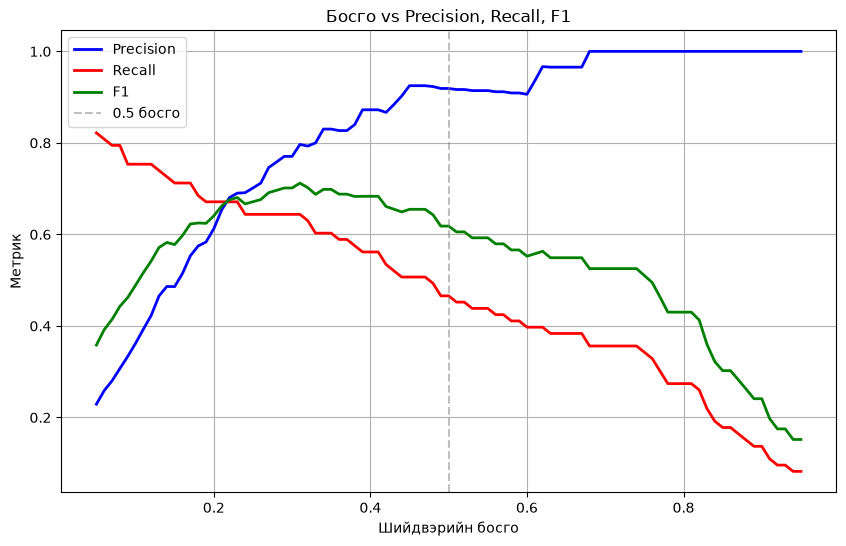

In [8]:
thresholds_fine = np.arange(0.05, 0.96, 0.01)
precisions = [evaluate_threshold(y_test, p_sklearn, t)['precision'] for t in thresholds_fine]
recalls = [evaluate_threshold(y_test, p_sklearn, t)['recall'] for t in thresholds_fine]
f1s = [evaluate_threshold(y_test, p_sklearn, t)['f1'] for t in thresholds_fine]

plt.figure(figsize=(10, 6))
plt.plot(thresholds_fine, precisions, 'b-', linewidth=2, label='Precision')
plt.plot(thresholds_fine, recalls, 'r-', linewidth=2, label='Recall')
plt.plot(thresholds_fine, f1s, 'g-', linewidth=2, label='F1')
plt.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='0.5 босго')
plt.xlabel('Шийдвэрийн босго')
plt.ylabel('Метрик')
plt.title('Босго vs Precision, Recall, F1')
plt.legend()
plt.grid(True)
plt.show()

### В2 — Тайлбар

**b) Тайлбар: босго доошлуулахад recall яагаад өсөж, precision яагаад буурч байна вэ?**
Босго доошлуулах үед илүү олон таамаглал "эерэг" (default) гэж ангилагдана. Энэ нь:
- **Recall нэмэгдэнэ:** Учир нь бодит default-уудын илүү их хувь нь барьгдана (FN буурна).
- **Precision буурна:** Учир нь нэмэлт таамаглалуудын дунд буруу дохиолол (FP) нэмэгдэнэ.

Энэ нь precision-recall trade-off-ийн сонгодог жишээ юм.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')

print("В3 — 5-fold кросс-валидацын AUC")
print("=" * 45)
for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score:.4f}")
print("-" * 45)
print(f"Дундаж: {cv_scores.mean():.3f}")
print(f"Стандарт хазайлт: {cv_scores.std():.3f}")
print(f"Хүлээгдэж буй: 0.870 ± 0.019")

В3 — 5-fold кросс-валидацын AUC
Fold 1: 0.8762
Fold 2: 0.8661
Fold 3: 0.8486
Fold 4: 0.9021
Fold 5: 0.8555
---------------------------------------------
Дундаж: 0.870
Стандарт хазайлт: 0.019
Хүлээгдэж буй: 0.870 ± 0.019


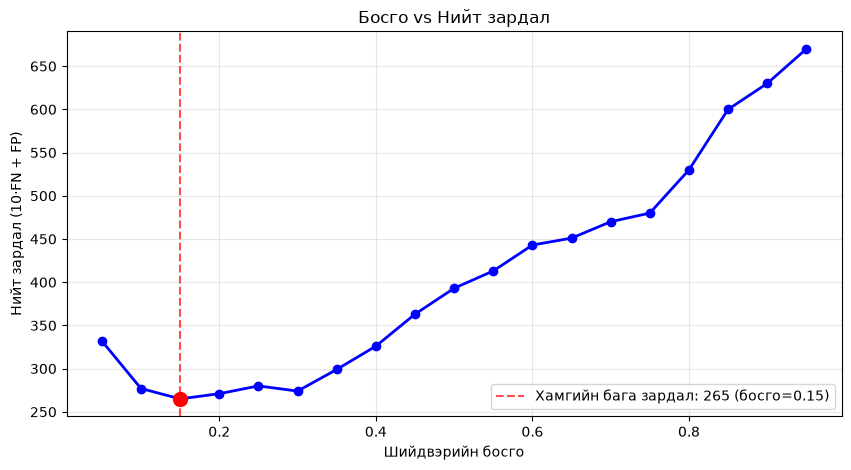

В4c — Зардал хамгийн бага байх босго: 0.15
Хамгийн бага зардал: 265
В4d — 0.5 босгон дээрх зардал: 393


In [10]:
def total_cost(y_true, p_pred, threshold):
    y_pred = (p_pred >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 10 * fn + fp

thresholds_cost = np.arange(0.05, 0.96, 0.05)
costs = [total_cost(y_test, p_sklearn, t) for t in thresholds_cost]

plt.figure(figsize=(10, 5))
plt.plot(thresholds_cost, costs, 'bo-', linewidth=2, markersize=6)
plt.xlabel('Шийдвэрийн босго')
plt.ylabel('Нийт зардал (10·FN + FP)')
plt.title('Босго vs Нийт зардал')
plt.grid(True, alpha=0.3)

min_idx = np.argmin(costs)
min_threshold = thresholds_cost[min_idx]
min_cost = costs[min_idx]
plt.axvline(x=min_threshold, color='r', linestyle='--', alpha=0.7, 
            label=f'Хамгийн бага зардал: {min_cost} (босго={min_threshold:.2f})')
plt.scatter([min_threshold], [min_cost], color='red', s=100, zorder=5)
plt.legend()
plt.show()

print(f"В4c — Зардал хамгийн бага байх босго: {min_threshold:.2f}")
print(f"Хамгийн бага зардал: {min_cost}")

cost_05 = total_cost(y_test, p_sklearn, 0.5)
print(f"В4d — 0.5 босгон дээрх зардал: {cost_05}")

### В4 — Тайлбар

**d) Асуулт: 0.5 босгон дээрх зардал хэд вэ, яагаад 0.5 нь «зөв» босго биш вэ?**
0.5 босгон дээр зардал = 10·39 + 3 = **393**. Энэ нь хамгийн бага зардал (265) -аас 128 нэгжээр өндөр.

0.5 нь «зөв» босго биш учир нь:
1. Энэ нь тэнцвэртэй датад зориулагдсан — default нь зөвхөн 7.3% байгаа тэнцвэргүй датад тохиромжгүй.
2. Зардлын тэгш бус байдал: нэг FN нь 10 нэгж, нэг FP нь 1 нэгж. Тиймээс FN-ийг бууруулах нь илүү чухал — 0.15 босго нь илүү олон default-ийг барьж, зардлыг бууруулна.
3. Бизнесийн хэрэгцээ: банк default-ийг алдахаас илүүтэйгээр илүү олон хүнийг шалгахыг хүснэ (хямд).